<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Aula_Interpolacao_Lagrange_Calculo_Numerico(7).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula: Interpolação Polinomial de Lagrange

> **Ideia central:** dados valores de uma função em pontos distintos, construímos um polinômio que passa exatamente por todos esses pontos.

## Objetivos de aprendizagem

Ao final da aula, espera-se que você consiga:

1. explicar o problema de interpolação e diferenciar interpolar de ajustar uma curva;
2. construir os polinômios fundamentais de Lagrange e o polinômio interpolador;
3. avaliar o polinômio em pontos intermediários;
4. verificar numericamente a interpolação e interpretar o erro;
5. reconhecer aplicações e limitações do método.



## 1. Motivação:

A **interpolação** constrói uma função que reproduz exatamente os dados conhecidos e permite estimar valores entre eles.

### Interpolação não é o mesmo que ajuste

- **Interpolação:** o modelo passa por todos os pontos fornecidos. É apropriada quando os valores tabulados devem ser reproduzidos exatamente.
- **Ajuste/regressão:** o modelo procura representar a tendência geral dos dados, sem necessariamente passar por cada ponto. É útil quando há ruído de medição.

A escolha depende do significado e da qualidade dos dados, não apenas da conveniência matemática.

### Uma primeira visualização

Considere os pontos \((0,1)\), \((1,3)\) e \((2,2)\). Existe um único polinômio de grau no máximo 2 que passa pelos três pontos. Vamos encontrá-lo e visualizar os dados.

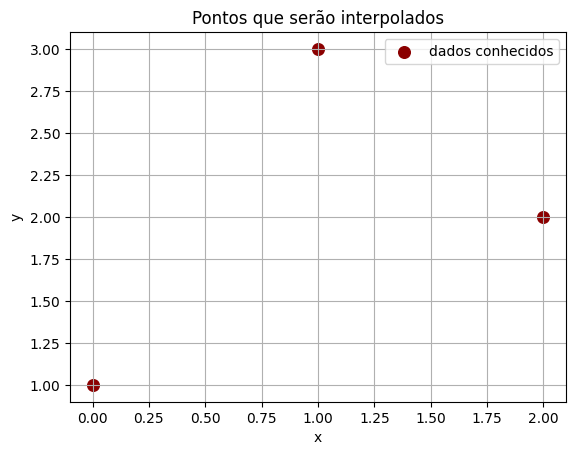

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x_dados = np.array([0.0, 1.0, 2.0])
y_dados = np.array([1.0, 3.0, 2.0])

plt.scatter(x_dados, y_dados, color="darkred", s=70, label="dados conhecidos")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pontos que serão interpolados")
plt.grid(True)
plt.legend()
plt.show()

## 2. Problema matemático

Imagine que conhecemos alguns valores de uma função, mas não sabemos sua expressão completa. Por exemplo, podemos conhecer os pontos obtidos por medições experimentais:

$$
(x_0,y_0),\ (x_1,y_1),\ \ldots,\ (x_n,y_n).
$$

Em cada par, $x_i$ representa a entrada e $y_i$ representa o valor correspondente. O objetivo da interpolação é construir uma função que passe exatamente por esses pontos.

Neste tópico, procuramos um polinômio $P_n(x)$ que satisfaça:

$$
P_n(x_i)=y_i,\qquad i=0,1,\ldots,n.
$$

Isso significa que, quando substituímos $x_0$ no polinômio, obtemos $y_0$; quando substituímos $x_1$, obtemos $y_1$; e assim por diante, até o último ponto.

### O que significa um polinômio de grau no máximo $n$?

Um polinômio de grau no máximo $n$ tem a forma:

$$
P_n(x)=a_0+a_1x+a_2x^2+\cdots+a_nx^n.
$$

Os números $a_0,a_1,\ldots,a_n$ são os coeficientes do polinômio. Eles são desconhecidos e precisam ser determinados para que o polinômio passe pelos pontos fornecidos.

Por exemplo, se temos três pontos, então $n=2$. Procuramos um polinômio de grau no máximo 2:

$$
P_2(x)=a_0+a_1x+a_2x^2.
$$

Os três coeficientes são determinados impondo que o polinômio passe pelos três pontos:

$$
P_2(x_0)=y_0,\qquad
P_2(x_1)=y_1,\qquad
P_2(x_2)=y_2.
$$

Cada condição fornece uma equação. Nesse exemplo, temos três equações para determinar os três coeficientes.

### Sistema de equações para os coeficientes

Substituindo cada nó $x_i$ na expressão geral do polinômio, obtemos:

$$
\begin{aligned}
a_0+a_1x_0+a_2x_0^2+\cdots+a_nx_0^n &= y_0,\\
a_0+a_1x_1+a_2x_1^2+\cdots+a_nx_1^n &= y_1,\\
&\vdots\\
a_0+a_1x_n+a_2x_n^2+\cdots+a_nx_n^n &= y_n.
\end{aligned}
$$

Portanto, encontrar o polinômio interpolador também pode ser entendido como resolver um sistema linear. Escrevendo esse sistema na forma matricial, temos:

$$
\begin{bmatrix}
1 & x_0 & x_0^2 & \cdots & x_0^n\\
1 & x_1 & x_1^2 & \cdots & x_1^n\\
\vdots & \vdots & \vdots & \ddots & \vdots\\
1 & x_n & x_n^2 & \cdots & x_n^n
\end{bmatrix}
\begin{bmatrix}
a_0\\
a_1\\
\vdots\\
a_n
\end{bmatrix}
=
\begin{bmatrix}
y_0\\
y_1\\
\vdots\\
y_n
\end{bmatrix}.
$$

A matriz desse sistema é chamada de **matriz de Vandermonde**. Resolver o sistema permite encontrar os coeficientes do polinômio.

### Por que os valores $x_i$ precisam ser distintos?

Os valores $x_0,x_1,\ldots,x_n$ são chamados de **nós de interpolação**. Eles precisam ser distintos, isto é:

$$
x_i\neq x_j\qquad\text{quando }i\neq j.
$$

Há duas razões principais para isso:

1. **Os dados precisam definir uma única saída para cada entrada.** Se o mesmo valor de $x$ estivesse associado a dois valores diferentes de $y$, não existiria uma função que passasse pelos dois pontos ao mesmo tempo.

2. **A fórmula de Lagrange contém diferenças entre os nós.** Seus denominadores incluem termos como $x_i-x_j$. Se $x_i=x_j$, essa diferença seria zero e haveria uma divisão por zero.

### Por que existe um único polinômio interpolador?

Um polinômio de grau no máximo $n$ possui $n+1$ coeficientes. Para determinar esses coeficientes, usamos as $n+1$ condições de interpolação:

$$
P_n(x_i)=y_i,\qquad i=0,1,\ldots,n.
$$

Quando os nós são distintos, o determinante da matriz de Vandermonde é diferente de zero:

$$
\det(V)=\prod_{0\leq i<j\leq n}(x_j-x_i)\neq 0.
$$

Isso garante que o sistema de equações tem uma única solução. Em outras palavras, existe exatamente um conjunto de coeficientes $a_0,a_1,\ldots,a_n$ que faz o polinômio passar por todos os pontos.

Assim, para $n+1$ pontos com valores de $x$ distintos, existe um único polinômio de grau no máximo $n$ que interpola esses pontos.

### Como a fórmula de Lagrange encontra esse polinômio?

Em vez de resolver diretamente o sistema de Vandermonde, podemos construir o polinômio usando polinômios auxiliares chamados **polinômios de Lagrange**.

Para cada nó $x_i$, construímos uma função $L_i(x)$ que vale 1 nesse nó e 0 em todos os outros:

$$
L_i(x_i)=1
$$

e

$$
L_i(x_j)=0\qquad\text{para }j\neq i.
$$

A função $L_i(x)$ funciona como um seletor: ao avaliar o polinômio no nó $x_i$, ela mantém o valor $y_i$; nos demais nós, sua contribuição é zero.

Somando as contribuições de todos os nós, obtemos:

$$
P_n(x)=\sum_{i=0}^{n}y_iL_i(x).
$$

Por exemplo, quando avaliamos essa expressão em $x_0$, temos:

$$
P_n(x_0)=y_0L_0(x_0)+y_1L_1(x_0)+\cdots+y_nL_n(x_0).
$$

Como $L_0(x_0)=1$ e $L_i(x_0)=0$ para $i\neq 0$, todos os termos desaparecem, exceto o primeiro:

$$
P_n(x_0)=y_0.
$$

O mesmo raciocínio vale para qualquer nó $x_k$. Portanto, o polinômio construído passa por todos os pontos conhecidos.

## 3. Polinômios fundamentais de Lagrange

Para construir o polinômio interpolador, primeiro definimos um polinômio auxiliar para cada nó $x_i$. Esse polinômio é chamado de **polinômio fundamental de Lagrange** ou **polinômio-base de Lagrange**.

Para o nó $x_i$, definimos:

$$
L_i(x)=\prod_{\substack{j=0\\j\neq i}}^{n}
\frac{x-x_j}{x_i-x_j}.
$$

O símbolo $\prod$ representa uma multiplicação de fatores. O índice $j$ percorre todos os nós, de $0$ até $n$, mas o fator correspondente a $j=i$ é excluído.

Assim, cada fator da expressão tem a forma:

$$
\frac{x-x_j}{x_i-x_j}.
$$

No numerador aparece a variável $x$ menos um dos nós. No denominador aparece a diferença entre o nó $x_i$ associado à base e esse mesmo nó $x_j$.

### Exemplo com três nós

Considere três nós distintos, $x_0$, $x_1$ e $x_2$. Para construir a base associada a $x_0$, usamos os outros dois nós nos fatores:

$$
L_0(x)=
\frac{x-x_1}{x_0-x_1}
\frac{x-x_2}{x_0-x_2}.
$$

Para a base associada a $x_1$, excluímos o fator com $j=1$:

$$
L_1(x)=
\frac{x-x_0}{x_1-x_0}
\frac{x-x_2}{x_1-x_2}.
$$

Para a base associada a $x_2$, excluímos o fator com $j=2$:

$$
L_2(x)=
\frac{x-x_0}{x_2-x_0}
\frac{x-x_1}{x_2-x_1}.
$$

Cada polinômio-base tem grau no máximo 2 e apresenta um comportamento específico nos três nós.

### Propriedade fundamental

O polinômio $L_i(x)$ vale 1 no nó $x_i$ e vale 0 em todos os outros nós. Em notação matemática:

$$
L_i(x_k)=
\begin{cases}
1, & \text{se } k=i,\\
0, & \text{se } k\neq i.
\end{cases}
$$

Essa propriedade pode ser verificada substituindo cada nó na fórmula.

### Por que $L_i(x_i)=1$?

Substituímos $x=x_i$ na definição de $L_i(x)$:

$$
L_i(x_i)=
\prod_{\substack{j=0\\j\neq i}}^{n}
\frac{x_i-x_j}{x_i-x_j}.
$$

Como os nós são distintos, cada denominador é diferente de zero. Cada fator é igual a 1:

$$
\frac{x_i-x_j}{x_i-x_j}=1.
$$

Portanto, o produto de todos esses fatores também é 1:

$$
L_i(x_i)=1.
$$

### Por que $L_i(x_k)=0$ quando $k\neq i$?

Agora substituímos $x=x_k$, considerando um nó $x_k$ diferente de $x_i$:

$$
L_i(x_k)=
\prod_{\substack{j=0\\j\neq i}}^{n}
\frac{x_k-x_j}{x_i-x_j}.
$$

Como $k\neq i$, o produto inclui o fator correspondente a $j=k$. Nesse fator, o numerador é:

$$
x_k-x_k=0.
$$

Logo, um dos fatores do produto é zero e, consequentemente:

$$
L_i(x_k)=0.
$$

### Interpretação: cada base atua como um seletor

O polinômio $L_i(x)$ seleciona o nó $x_i$:

- no próprio nó $x_i$, seu valor é 1;
- nos outros nós, seu valor é 0.

Por isso, ao multiplicarmos $L_i(x)$ pelo valor correspondente $y_i$, obtemos uma contribuição que reproduz $y_i$ em $x_i$ e não altera os valores nos demais nós.

Somando as contribuições de todos os nós, obtemos o polinômio interpolador de Lagrange:

$$
P_n(x)=\sum_{i=0}^{n}y_iL_i(x).
$$

### Verificação nos nós

Para verificar que essa expressão interpola os dados, avaliamos $P_n(x)$ em um nó qualquer $x_k$:

$$
P_n(x_k)=\sum_{i=0}^{n}y_iL_i(x_k).
$$

Todos os termos da soma são zero, exceto o termo para o qual $i=k$, pois:

$$
L_i(x_k)=0\quad\text{se }i\neq k,
\qquad
L_k(x_k)=1.
$$

Assim:

$$
P_n(x_k)=y_k.
$$

Como isso vale para cada nó $x_k$, o polinômio $P_n(x)$ passa por todos os pontos da tabela.

> **Atenção:** os denominadores da fórmula contêm diferenças entre os nós. Por isso, os nós precisam ser distintos. Se dois nós fossem iguais, algum denominador seria zero.